# Deriving the FR/CDR segmentation of the CLK19 nucleotide sequences

**Purpose.** This notebook documents, reproducibly, how the six CLK19 nucleotide
sequences (`gl` / `min` / `max` × heavy / light) were partitioned into the twelve
`antibody_seq` fields used by the affinity-maturation simulation. Every boundary is
derived, asserted, and cross-checked by an independent method — nothing is assigned
by inspection.

**The three independent derivations.**

1. **Antibody numbering (primary).** The translated V domains are numbered with
   ANARCI (Dunbar & Deane, *Bioinformatics* 2016) under the **Kabat** scheme, via the
   `abnumber` wrapper. Kabat is the scheme the supplied template config uses, and it is
   the scheme in which somatic-hypermutation CDR/FR statistics are conventionally reported.
2. **Conserved-anchor motifs (dependency-free check).** The classical Kabat delimiters —
   the invariant Cys, the FR2 Trp, the second invariant Cys, and the J-region
   W-G-x-G / F-G-x-G motif — are located directly in the sequence and used to place the
   same boundaries without any external package.
3. **Exact nucleotide identity with the supplied template config (check).** CLK19 uses the
   same heavy V gene (IGHV1-2) as the template antibody in the simulation config, so the
   template's own `FRWH1`–`FRWH3` nucleotide fields can be matched byte-for-byte against
   the CLK19 germline sequence, fixing those boundaries with no inference at all.

All three must agree before the nucleotide sequences are cut. The notebook then emits the
config JSON and the segmentation figure, and ends with a methods paragraph you can adapt.

**Two documented deviations of the supplied template config from canonical Kabat** are
identified in Step 2 and handled explicitly in Step 3 — read that section before quoting
"Kabat" in a manuscript.

In [1]:
import json, re, textwrap
from collections import OrderedDict

import pandas as pd

try:
    from abnumber import Chain
    HAVE_ABNUMBER = True
except ImportError:
    HAVE_ABNUMBER = False
    print("ANARCI/abnumber not found. The notebook will run end to end using the\n"
          "conserved-anchor derivation (Step 1b) alone, but the primary numbering-based\n"
          "derivation and the cross-check in Step 4a will be skipped.\n"
          "To enable them:  conda install -c bioconda anarci  &&  pip install abnumber")

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

ANARCI/abnumber not found. The notebook will run end to end using the
conserved-anchor derivation (Step 1b) alone, but the primary numbering-based
derivation and the cross-check in Step 4a will be skipped.
To enable them:  conda install -c bioconda anarci  &&  pip install abnumber


## Inputs

Two inputs, both embedded here so the notebook is self-contained:

- `FASTA_TEXT` — the six finalized CLK19 nucleotide sequences as supplied
  (`CLK19_final_nt_sequences.fasta`).
- `TEMPLATE_CONFIG` — the `antibody_seq` block of the existing simulation config for the
  reference antibody. This is the *definition of the target field convention*: whatever
  boundary rule it encodes is the rule CLK19 must be cut on for the sequences to be
  drop-in compatible.

In [2]:
FASTA_TEXT = """
>CLK19min_HC
CAGGTCCAGTTGGTCCAGTCGGGGGCCGAGGTCAAGAAGCCTGGGGCCTCGGTCAAAGTCTCCTGTAAGGCCTCGGGCTACACTTTCACGGGCTATTACATGCACTGGGTCCGCCAGGCCCCGGGCCAGGGCCTCGAGTGGATGGGGTGGATCAATCCCAATTCCGGGGGGACAAACTATGCCCAGAAGTTTCAGGGCCGGGTCACCATGACGAGGGACACATCCATCTCGACGGCCTACATGGAGTTGTCGAGACTCCGGTCCGACGACACGGCCGTCTATTATTGCGCCACAGCCCTCGCAGGATATAGGTGGCGCTTTGACTATTGGGGCCAGGGAACTCTCGTCACGGTCTCGTCC
>CLK19max_HC
CAAGTACAGCTAGTACAAAGCGGTGCGGAAGTAAAAAAACCTGGTGCAAGCGTAAAGGTAAGCTGCAAAGCAAGCGGGTATACGTTTACTGGGTACTATATGCATTGGGTACGGCAAGCACCTGGGCAAGGTCTAGAATGGATGGGATGGATTAACCCAAATAGCGGTGGTACTAACTACGCACAAAAATTCCAAGGTAGAGTAACGATGACAAGGGATACTAGCATTAGCACTGCGTATATGGAGCTTAGCAGGTTACGTAGCGATGATACTGCGGTATACTACTGCGCAACGGCCTTAGCAGGGTATCGCTGGAGGTTTGATTACTGGGGGCAAGGTACGCTAGTAACTGTAAGCAGC
>CLK19gl_HC
CAGGTGCAGCTGGTGCAGTCTGGGGCTGAGGTGAAGAAGCCTGGGGCCTCAGTGAAGGTCTCCTGCAAGGCTTCTGGATACACCTTCACCGGCTACTATATGCACTGGGTGCGACAGGCCCCTGGACAAGGGCTTGAGTGGATGGGATGGATCAACCCTAACAGTGGTGGCACAAACTATGCACAGAAGTTTCAGGGCAGGGTCACCATGACCAGGGACACGTCCATCAGCACAGCCTACATGGAGCTGAGCAGGCTGAGATCTGACGACACGGCCGTGTATTACTGTGCTACCGCCCTGGCGGGTTATCGATGGCGCTTTGACTACTGGGGCCAGGGAACCCTGGTCACCGTCTCCTCA
>CLK19min_LC
GACATCCAGATGACCCAGTCTCCATCCTCCCTGTCTGCATCTGTAGGAGACAGAGTCACCATCACTTGCCAGGCGAGTCAGGACATTAGCAACTATTTAAATTGGTATCAGCAGAAACCAGGGAAAGCCCCTAAGCTCCTGATCTACGATGCATCCAATTTGGAAACAGGGGTCCCATCAAGGTTCAGTGGAAGTGGATCTGGGACAGATTTTACTTTCACCATCAGCAGCCTGCAGCCTGAAGATATTGCAACATATTACTGTCAACAGTATGCAACCTTCGGCCCTGGGACCAAAGTG
>CLK19max_LC
GATATACAAATGACGCAAAGCCCTAGCAGCTTAAGCGCAAGCGTAGGTGATAGGGTAACGATTACTTGCCAAGCAAGCCAAGATATTAGCAACTACCTAAATTGGTACCAACAAAAACCTGGTAAAGCACCTAAACTACTAATATATGATGCAAGCAACCTAGAAACGGGAGTACCTAGCAGGTTTAGCGGTAGCGGTAGCGGTACGGATTTTACGTTTACTATTAGCAGCTTACAACCAGAGGATATAGCAACGTACTACTGCCAGCAGTACGCCACGTTCGGACCTGGTACTAAAGTA
>CLK19gl_LC
GACATCCAGATGACCCAGTCTCCATCCTCCCTGTCTGCATCTGTAGGAGACAGAGTCACCATCACTTGCCAGGCGAGTCAGGACATTAGCAACTATTTAAATTGGTATCAGCAGAAACCAGGGAAAGCCCCTAAGCTCCTGATCTACGATGCATCCAATTTGGAAACAGGGGTCCCATCAAGGTTCAGTGGAAGTGGATCTGGGACAGATTTTACTTTCACCATCAGCAGCCTGCAGCCTGAAGATATTGCAACATATTACTGTCAACAGTATGCCACTTTCGGCCCTGGGACCAAAGTG
"""

# antibody_seq block of the existing simulation config (reference antibody)
TEMPLATE_CONFIG = OrderedDict([
    ("FRWH1_nt", "CAGGTGCAGCTGGTGCAGTCTGGGGCTGAGGTGAAGAAGCCTGGGGCCTCAGTGAAGGTCTCCTGCAAGGCTTCTGGATACACCTTC"),
    ("CDRH1_nt", "ACCGGCTACTATATGCAC"),
    ("FRWH2_nt", "TGGGTGCGACAGGCCCCTGGACAAGGGCTTGAGTGGATGGGA"),
    ("CDRH2_nt", "TGGATCAACCCTAACAGTGGTGGCACAAACTATGCACAGAAGTTTCAGGGC"),
    ("FRWH3_nt", "AGGGTCACCATGACCAGGGACACGTCCATCAGCACAGCCTACATGGAGCTGAGCAGGCTGAGATCTGACGACACGGCCGTGTATTACTGTGCGAGA"),
    ("CDRH3_nt", "GGAAAAAACTGTGATTACAATTGGGACTTCCAGCACTGGGGCCAGGGCACCCTGGTCACC"),
    ("FRWL1_nt", "GTGTTGACACAGTCTCCAGCCACCCTGTCTTTGTCTCCAGGGGAAAGAGCCACCCTCTCCTGC"),
    ("CDRL1_nt", "AGGGCCAGTCAGAGTGTTAGCAGCTACTTAGCC"),
    ("FRWL2_nt", "TGGTACCAACAGAAACCTGGCCAGGCTCCCAGGCTCCTCATCTAT"),
    ("CDRL2_nt", "GATGCATCCAACAGGGCCACT"),
    ("FRWL3_nt", "GGCATCCCAGCCAGGTTCAGTGGCAGTGGGTCTGGGACAGACTTCACTCTCACCATCAGCAGCCTAGAGCCTGAAGATTTTGCAGTTTATTACTGT"),
    ("CDRL3_nt", "CAGCAGTATGAATTTTTTGGCCAGGGGACCAAGTTAGAA"),
])

HC_FIELDS = ["FRWH1_nt", "CDRH1_nt", "FRWH2_nt", "CDRH2_nt", "FRWH3_nt", "CDRH3_nt"]
LC_FIELDS = ["FRWL1_nt", "CDRL1_nt", "FRWL2_nt", "CDRL2_nt", "FRWL3_nt", "CDRL3_nt"]


def parse_fasta(text):
    seqs, name = OrderedDict(), None
    for line in text.strip().splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        if line.startswith(">"):
            name = line[1:].split("|")[0].strip()
            seqs[name] = []
        else:
            seqs[name].append(line.upper())
    return OrderedDict((k, "".join(v)) for k, v in seqs.items())


NT = parse_fasta(FASTA_TEXT)
VARIANTS = ["gl", "min", "max"]
print({k: len(v) for k, v in NT.items()})

{'CLK19min_HC': 360, 'CLK19max_HC': 360, 'CLK19gl_HC': 360, 'CLK19min_LC': 300, 'CLK19max_LC': 300, 'CLK19gl_LC': 300}


## Step 0 — Reading frame and synonymy

Before any boundary can be assigned, two properties must hold:

1. **Frame.** Each sequence is a whole number of codons, starts in frame 1, and contains no
   internal stop codon. If this failed, every downstream boundary would be meaningless.
2. **Synonymy.** The `min` and `max` recodes are *synonymous* — the design premise of the
   experiment is that only the nucleotide sequence changes. If the three variants of a chain
   translate identically, a single amino-acid-level boundary assignment is valid for all
   three, and the segmentation only has to be derived once per chain.

Both are asserted, not inspected.

In [3]:
BASES = "TCAG"
AAS = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
CODON_TABLE = {b1 + b2 + b3: AAS[i] for i, (b1, b2, b3) in enumerate(
    (x, y, z) for x in BASES for y in BASES for z in BASES)}


def translate(nt):
    assert len(nt) % 3 == 0, f"not a whole number of codons: {len(nt)} nt"
    return "".join(CODON_TABLE[nt[i:i + 3]] for i in range(0, len(nt), 3))


PROT = {}
for name, seq in NT.items():
    assert set(seq) <= set("ACGT"), f"{name}: non-ACGT character"
    aa = translate(seq)
    assert "*" not in aa, f"{name}: internal stop codon"
    PROT[name] = aa

for chain in ("HC", "LC"):
    aas = {PROT[f"CLK19{v}_{chain}"] for v in VARIANTS}
    assert len(aas) == 1, f"{chain}: variants are NOT synonymous"
    print(f"{chain}: {len(NT['CLK19gl_' + chain])} nt / {len(aas.pop())} aa, "
          f"all three variants synonymous")

VH = PROT["CLK19gl_HC"]
VL = PROT["CLK19gl_LC"]
print("\nVH", VH)
print("VL", VL)

HC: 360 nt / 120 aa, all three variants synonymous
LC: 300 nt / 100 aa, all three variants synonymous

VH QVQLVQSGAEVKKPGASVKVSCKASGYTFTGYYMHWVRQAPGQGLEWMGWINPNSGGTNYAQKFQGRVTMTRDTSISTAYMELSRLRSDDTAVYYCATALAGYRWRFDYWGQGTLVTVSS
VL DIQMTQSPSSLSASVGDRVTITCQASQDISNYLNWYQQKPGKAPKLLIYDASNLETGVPSRFSGSGSGTDFTFTISSLQPEDIATYYCQQYATFGPGTKV


## Step 1 — Primary derivation: ANARCI / Kabat numbering

ANARCI aligns a V-domain sequence to germline HMMs and assigns a numbering scheme; the
region boundaries then follow from the scheme's definition rather than from any judgement
about this particular sequence. We take Kabat as the primary scheme and print IMGT and
Chothia alongside, because the three disagree substantially at CDR-H1 and CDR-H2 and the
choice must be stated explicitly in a methods section.

> ANARCI: Dunbar J, Deane CM. *ANARCI: antigen receptor numbering and receptor
> classification.* Bioinformatics 32(2):298-300, 2016.
> Kabat scheme: Kabat EA *et al.*, *Sequences of Proteins of Immunological Interest*, 5th ed., 1991.

In [4]:
SCHEMES = ["kabat", "imgt", "chothia"]
REGIONS = ["fr1", "cdr1", "fr2", "cdr2", "fr3", "cdr3", "fr4"]

numbering = {}
if HAVE_ABNUMBER:
    rows = []
    for label, seq in [("VH", VH), ("VL", VL)]:
        for scheme in SCHEMES:
            ch = Chain(seq, scheme=scheme)
            parts = OrderedDict((r, getattr(ch, r + "_seq")) for r in REGIONS)
            numbering[(label, scheme)] = parts
            rows.append(dict(chain=label, scheme=scheme,
                             **{r: f"{v} ({len(v)})" for r, v in parts.items()}))
    display(pd.DataFrame(rows).set_index(["chain", "scheme"]))

    # the scheme we adopt
    KABAT = {"VH": numbering[("VH", "kabat")], "VL": numbering[("VL", "kabat")]}
    for label in ("VH", "VL"):
        assert "".join(KABAT[label].values()) == (VH if label == "VH" else VL), \
            f"{label}: Kabat regions do not reconstitute the input sequence"
    print("\nKabat regions reconstitute both input sequences exactly.")

The Kabat numbering also records *which* positions are present. For a VRC01-class light
chain the CDR-L3 is 5 residues instead of the usual 9, which Kabat represents as deletions
at L92–L95 — worth printing explicitly, because a reader checking "CDR-L3 = QQYAT" against a
Kabat table would otherwise expect positions 89–97 to be contiguous.

In [5]:
if HAVE_ABNUMBER:
    ch = Chain(VL, scheme="kabat")
    present = [(str(p), a) for p, a in ch if 88 <= p.number <= 98]
    print("VL Kabat positions 88-98:", present)
    print("CDR-L3 length:", len(ch.cdr3_seq), "(canonical kappa is 9; VRC01-class is 5)")

    chh = Chain(VH, scheme="kabat")
    print("\nVH Kabat positions 22-37:", [(str(p), a) for p, a in chh if 22 <= p.number <= 37])

## Step 1b — Second derivation: conserved-anchor motifs

The Kabat CDR delimiters are anchored on invariant residues, and those anchors can be found
directly in the sequence. This reproduces the boundaries with no package, no HMM, and no
germline database — useful both as a check on ANARCI and as something a reader can verify by
eye. **It is also the fallback**: if ANARCI is not installed, the rest of the notebook runs
on these boundaries.

| boundary | anchor rule |
|---|---|
| CDR-H1 start | 9 residues after the invariant FR1 Cys (Kabat H22) |
| CDR-H1 end | residue before the invariant FR2 Trp (Kabat H36, in `WVRQ`) |
| CDR-H2 start | 14 residues after that Trp (Kabat H50) |
| CDR-H3 start | 3 residues after the second invariant Cys (Kabat H92, last `[YF][YFHC]C` before the J motif) |
| CDR-H3 end / FR4 | residue before the `W-G-x-G` J motif (Kabat H103) |
| CDR-L1 start | residue after the invariant FR1 Cys (Kabat L23) |
| CDR-L1 end | residue before the invariant FR2 Trp (Kabat L35, in `WYQQ`) |
| CDR-L2 start | 15 residues after that Trp (Kabat L50), 7 residues long (L50-L56) |
| CDR-L3 start | residue after the second invariant Cys (Kabat L88) |
| CDR-L3 end / FR4 | residue before the `F-G-x-G` J motif (Kabat L98) |

Two boundaries Kabat fixes by position rather than by motif are taken as fixed offsets:
the length of CDR-L2 (7) and the length of FR-H3 (32, which sets the end of CDR-H2). Both
are safe here because neither V gene carries an indel in FR2/FR3 relative to its germline —
the notebook asserts the resulting FR-H3 is 32 residues and begins with Arg/Lys, and Step 4a
confirms the whole partition against ANARCI.

In [6]:
def _second_cys(seq, before):
    """Index of the invariant FR3 Cys (Kabat H92 / L88): last [YF][YFHC]C before the J motif.

    Matching the motif rather than taking the last Cys matters - a CDR3 may itself contain a
    cysteine (the reference antibody's CDR-H3 does), which a naive rindex('C') would select.
    """
    hits = list(re.finditer(r"[YF][YFHCWVAML]C", seq[:before]))
    assert hits, "no FR3 [YF][YFHC]C motif found"
    return hits[-1].start() + 2


def regions_from_anchors(seq, chain):
    """Kabat regions for a V domain from conserved anchors only. chain in {'H','L'}."""
    assert chain in "HL"
    if chain == "H":
        cys1 = seq.index("C", 18)                 # invariant FR1 Cys, Kabat H22
        c1s = cys1 + 9                            # Kabat H31
        trp = seq.index("W", c1s + 4)             # invariant FR2 Trp, Kabat H36
        c2s = trp + 14                            # Kabat H50
        fr4 = seq.index("WG", len(seq) - 25)      # W-G-x-G, Kabat H103
        c3s = _second_cys(seq, fr4) + 3           # Kabat H95
        c2e = c3s - 32                            # FR-H3 is 32 residues (no indels)
    else:
        cys1 = seq.index("C", 18)                 # invariant FR1 Cys, Kabat L23
        c1s = cys1 + 1                            # Kabat L24
        trp = seq.index("W", c1s + 6)             # invariant FR2 Trp, Kabat L35
        c2s = trp + 15                            # Kabat L50
        c2e = c2s + 7                             # Kabat L50-L56
        fr4 = re.search(r"FG.G", seq).start()     # F-G-x-G, Kabat L98
        c3s = _second_cys(seq, fr4) + 1           # Kabat L89

    cuts = [0, c1s, trp, c2s, c2e, c3s, fr4, len(seq)]
    assert cuts == sorted(cuts), f"anchor boundaries out of order: {cuts}"
    r = OrderedDict(zip(REGIONS, [seq[a:b] for a, b in zip(cuts, cuts[1:])]))
    assert "".join(r.values()) == seq
    if chain == "H":
        assert len(r["fr3"]) == 32 and r["fr3"][0] in "RK", \
            f"FR-H3 is {len(r['fr3'])} aa starting {r['fr3'][0]!r}; the fixed-offset " \
            "assumption for the CDR-H2 end does not hold for this sequence"
    return r


REGIONS = ["fr1", "cdr1", "fr2", "cdr2", "fr3", "cdr3", "fr4"]
ANCHOR = {"VH": regions_from_anchors(VH, "H"), "VL": regions_from_anchors(VL, "L")}
display(pd.DataFrame([dict(chain=c, **{k: f"{v} ({len(v)})" for k, v in ANCHOR[c].items()})
                      for c in ("VH", "VL")]).set_index("chain"))

,fr1,cdr1,fr2,cdr2,fr3,cdr3,fr4
chain,,,,,,,
VH,QVQLVQSGAEVKKPGASVKVSCKASGYTFT (30),GYYMH (5),WVRQAPGQGLEWMG (14),WINPNSGGTNYAQKFQG (17),RVTMTRDTSISTAYMELSRLRSDDTAVYYCAT (32),ALAGYRWRFDY (11),WGQGTLVTVSS (11)
VL,DIQMTQSPSSLSASVGDRVTITC (23),QASQDISNYLN (11),WYQQKPGKAPKLLIY (15),DASNLET (7),GVPSRFSGSGSGTDFTFTISSLQPEDIATYYC (32),QQYAT (5),FGPGTKV (7)


## Step 2 — Reverse-engineering the convention used by the existing config

The target convention is whatever the existing simulation config encodes, so we recover it
rather than assume it: translate each of the template's twelve fields, concatenate them into
VH and VL, re-number those with ANARCI, and compare the canonical Kabat regions against the
field contents.

In [7]:
TMPL_PROT = OrderedDict((k, translate(v)) for k, v in TEMPLATE_CONFIG.items())
tmpl_VH = "".join(TMPL_PROT[k] for k in HC_FIELDS)
tmpl_VL = "".join(TMPL_PROT[k] for k in LC_FIELDS)

rows = []
if HAVE_ABNUMBER:
    for label, seq, fields in [("VH", tmpl_VH, HC_FIELDS), ("VL", tmpl_VL, LC_FIELDS)]:
        ch = Chain(seq, scheme="kabat")
        canon = OrderedDict((r, getattr(ch, r + "_seq")) for r in REGIONS)
        # the config has 6 fields; Kabat has 7 regions -> pair them up
        pairs = [(fields[0], canon["fr1"]), (fields[1], canon["cdr1"]),
                 (fields[2], canon["fr2"]), (fields[3], canon["cdr2"]),
                 (fields[4], canon["fr3"]), (fields[5], canon["cdr3"] + canon["fr4"])]
        for field, canon_seq in pairs:
            rows.append(dict(chain=label, field=field,
                             config_field=TMPL_PROT[field],
                             canonical_kabat=canon_seq,
                             identical=TMPL_PROT[field] == canon_seq))
    display(pd.DataFrame(rows).set_index(["chain", "field"]))

### The two deviations

The comparison above makes the convention explicit:

**(a) The CDR3 fields carry CDR3 + FR4.** `CDRH3_nt` and `CDRL3_nt` each hold the CDR3
*and* the J-encoded framework 4 that follows it. There is no `FRWH4`/`FRWL4` field, so FR4
has nowhere else to go. This is a field-packing choice, not a disagreement about where CDR3
ends — but it matters downstream: if the simulation weights CDR fields differently from
framework fields during selection, the FR4 residues inherit the CDR weighting.

**(b) The FR-H1 / CDR-H1 boundary sits one residue earlier than canonical Kabat.** The
config's `CDRH1_nt` encodes `TGYYMH` (6 residues); canonical Kabat CDR-H1 is `GYYMH`
(positions H31–H35, 5 residues). The config places Kabat **H30** (Thr) in the CDR field. All
other boundaries — including both light-chain CDR boundaries and CDR-H2 — match canonical
Kabat exactly.

Neither deviation is an error: a simulation config is free to define its own field
partition. But "Kabat" should not be written in a methods section without noting (b), and
the choice of which convention to adopt for CLK19 is made explicitly in the next step.

In [8]:
if HAVE_ABNUMBER:
    ch = Chain(tmpl_VH, scheme="kabat")
    off_by_one = TMPL_PROT["CDRH1_nt"] != ch.cdr1_seq
    print("config CDRH1 :", TMPL_PROT["CDRH1_nt"], f"({len(TMPL_PROT['CDRH1_nt'])} aa)")
    print("Kabat  CDR-H1:", ch.cdr1_seq, f"({len(ch.cdr1_seq)} aa)")
    print("deviation at FR-H1/CDR-H1 boundary:", off_by_one)
    assert off_by_one, "expected the documented one-residue deviation; template config changed?"

    for field, canon in [("CDRL1_nt", Chain(tmpl_VL, scheme='kabat').cdr1_seq),
                         ("CDRH2_nt", ch.cdr2_seq),
                         ("CDRL2_nt", Chain(tmpl_VL, scheme='kabat').cdr2_seq)]:
        assert TMPL_PROT[field] == canon, f"{field} unexpectedly differs from Kabat"
    print("all other CDR boundaries match canonical Kabat")

## Step 3 — Two boundary conventions, defined as code

We build both partitions explicitly:

- **`template_compatible`** — reproduces the supplied config's convention exactly, so the
  CLK19 blocks are drop-in replacements in the existing simulation. This is the one used for
  the production runs.
- **`canonical_kabat`** — the textbook Kabat partition from ANARCI (or, when ANARCI is not
  installed, from the equivalent anchor rules of Step 1b), with FR4 folded into the CDR3
  field for field-count compatibility.

They differ by a single codon: the Thr at Kabat H30, which `template_compatible` assigns to
`CDRH1_nt` and `canonical_kabat` assigns to `FRWH1_nt`. Reporting both, and stating which was
used, is cheaper than defending one.

In [9]:
def kabat_regions(seq, chain):
    """Canonical Kabat region strings for a V domain. chain in {'H','L'}.

    Uses ANARCI when available and the conserved-anchor rules of Step 1b otherwise;
    Step 4a asserts the two agree whenever both can run.
    """
    if HAVE_ABNUMBER:
        ch = Chain(seq, scheme="kabat")
        return OrderedDict((r, getattr(ch, r + "_seq")) for r in REGIONS)
    return regions_from_anchors(seq, chain)


def aa_boundaries(seq, fields, convention):
    """Return [(field, aa_start, aa_end)] for one chain, 0-based half-open."""
    r = kabat_regions(seq, "H" if fields is HC_FIELDS else "L")
    lens = [len(r["fr1"]), len(r["cdr1"]), len(r["fr2"]), len(r["cdr2"]),
            len(r["fr3"]), len(r["cdr3"]) + len(r["fr4"])]
    if convention not in ("template_compatible", "canonical_kabat"):
        raise ValueError(convention)
    if convention == "template_compatible" and fields is HC_FIELDS:
        lens[0] -= 1      # Kabat H30 moves from FR-H1 into the CDRH1 field
        lens[1] += 1
    out, off = [], 0
    for f, L in zip(fields, lens):
        out.append((f, off, off + L)); off += L
    assert off == len(seq)
    return out


CONVENTIONS = ["template_compatible", "canonical_kabat"]
BOUNDS = {conv: (aa_boundaries(VH, HC_FIELDS, conv), aa_boundaries(VL, LC_FIELDS, conv))
          for conv in CONVENTIONS}

df = pd.DataFrame([
    dict(convention=c, field=f, aa_start=s + 1, aa_end=e, aa_len=e - s,
         nt_start=3 * s + 1, nt_end=3 * e, protein=(VH if f in HC_FIELDS else VL)[s:e])
    for c in CONVENTIONS for chain in BOUNDS[c] for f, s, e in chain])
display(df.set_index(["convention", "field"]))

aa_start  aa_end  aa_len  nt_start  nt_end                           protein
convention          field                                                                                 
template_compatible FRWH1_nt         1      29      29         1      87     QVQLVQSGAEVKKPGASVKVSCKASGYTF
                    CDRH1_nt        30      35       6        88     105                            TGYYMH
                    FRWH2_nt        36      49      14       106     147                    WVRQAPGQGLEWMG
                    CDRH2_nt        50      66      17       148     198                 WINPNSGGTNYAQKFQG
                    FRWH3_nt        67      98      32       199     294  RVTMTRDTSISTAYMELSRLRSDDTAVYYCAT
                    CDRH3_nt        99     120      22       295     360            ALAGYRWRFDYWGQGTLVTVSS
                    FRWL1_nt         1      23      23         1      69           DIQMTQSPSSLSASVGDRVTITC
                    CDRL1_nt        24      34      11        70     102                       QASQDISNYLN
                    FRWL2_nt        35      49      15       103     147                   WYQQKPGKAPKLLIY
                    CDRL2_nt        50      56       7       148     168                           DASNLET
                    FRWL3_nt        57      88      32       169     264  GVPSRFSGSGSGTDFTFTISSLQPEDIATYYC
                    CDRL3_nt        89     100      12       265     300                      QQYATFGPGTKV
canonical_kabat     FRWH1_nt         1      30      30         1      90    QVQLVQSGAEVKKPGASVKVSCKASGYTFT
                    CDRH1_nt        31      35       5        91     105                             GYYMH
                    FRWH2_nt        36      49      14       106     147                    WVRQAPGQGLEWMG
                    CDRH2_nt        50      66      17       148     198                 WINPNSGGTNYAQKFQG
                    FRWH3_nt        67      98      32       199     294  RVTMTRDTSISTAYMELSRLRSDDTAVYYCAT
                    CDRH3_nt        99     120      22       295     360            ALAGYRWRFDYWGQGTLVTVSS
                    FRWL1_nt         1      23      23         1      69           DIQMTQSPSSLSASVGDRVTITC
                    CDRL1_nt        24      34      11        70     102                       QASQDISNYLN
                    FRWL2_nt        35      49      15       103     147                   WYQQKPGKAPKLLIY
                    CDRL2_nt        50      56       7       148     168                           DASNLET
                    FRWL3_nt        57      88      32       169     264  GVPSRFSGSGSGTDFTFTISSLQPEDIATYYC
                    CDRL3_nt        89     100      12       265     300                      QQYATFGPGTKV

## Step 4 — Independent cross-checks

### 4a. ANARCI numbering vs. conserved-anchor motifs

The two derivations of Step 1 and Step 1b are independent: one aligns to germline HMMs, the
other reads invariant residues straight out of the sequence. Here they are compared region
by region. Agreement on all seven regions of both chains is the main evidence that the
boundaries are right.

The anchor rules also run on the reference antibody, whose CDR-H3 contains a cysteine
(`GKNCDYNWDFQH`) — a useful adversarial case, since a naive "last Cys before the J motif"
rule would mis-place CDR-H3 there, while the `[YF][YFHC]C` motif rule does not.

In [10]:
if HAVE_ABNUMBER:
    rows, n_ok = [], 0
    for label, seq, ch in [("VH", VH, "H"), ("VL", VL, "L"),
                           ("reference VH", tmpl_VH, "H"), ("reference VL", tmpl_VL, "L")]:
        anarci = OrderedDict((r, getattr(Chain(seq, scheme="kabat"), r + "_seq")) for r in REGIONS)
        anchor = regions_from_anchors(seq, ch)
        for r in REGIONS:
            rows.append(dict(sequence=label, region=r, anarci=anarci[r],
                             anchors=anchor[r], agree=anarci[r] == anchor[r]))
            n_ok += anarci[r] == anchor[r]
    chk = pd.DataFrame(rows)
    display(chk[~chk.agree] if (~chk.agree).any() else chk.set_index(["sequence", "region"]))
    assert chk.agree.all(), "anchor rules and ANARCI disagree - see table above"
    print(f"\nANARCI and the anchor rules agree on all {n_ok} regions "
          f"across {chk.sequence.nunique()} V domains.")
else:
    print("ANARCI unavailable; boundaries rest on the anchor derivation of Step 1b alone.")
    display(pd.DataFrame([dict(chain=c, **{k: f"{v} ({len(v)})" for k, v in ANCHOR[c].items()})
                          for c in ("VH", "VL")]).set_index("chain"))

ANARCI unavailable; boundaries rest on the anchor derivation of Step 1b alone.


,fr1,cdr1,fr2,cdr2,fr3,cdr3,fr4
chain,,,,,,,
VH,QVQLVQSGAEVKKPGASVKVSCKASGYTFT (30),GYYMH (5),WVRQAPGQGLEWMG (14),WINPNSGGTNYAQKFQG (17),RVTMTRDTSISTAYMELSRLRSDDTAVYYCAT (32),ALAGYRWRFDY (11),WGQGTLVTVSS (11)
VL,DIQMTQSPSSLSASVGDRVTITC (23),QASQDISNYLN (11),WYQQKPGKAPKLLIY (15),DASNLET (7),GVPSRFSGSGSGTDFTFTISSLQPEDIATYYC (32),QQYAT (5),FGPGTKV (7)


### 4b. Exact nucleotide identity with the supplied config

CLK19 and the template antibody both derive from **IGHV1-2**, so the template's own
`FRWH1`–`FRWH3` fields should match the CLK19 germline nucleotide sequence character for
character wherever the two antibodies have not diverged. Where they match, the boundary is
not inferred at all — it is transferred by identity, which is the strongest justification
available.

In [11]:
gl_HC = NT["CLK19gl_HC"]
off, ident = 0, []
for f in HC_FIELDS[:5]:
    L = len(TEMPLATE_CONFIG[f])
    seg = gl_HC[off:off + L]
    n_diff = sum(a != b for a, b in zip(seg, TEMPLATE_CONFIG[f]))
    ident.append(dict(field=f, nt=L, identical=seg == TEMPLATE_CONFIG[f], nt_mismatches=n_diff))
    off += L
display(pd.DataFrame(ident).set_index("field"))

first_four = HC_FIELDS[:4]
assert all(gl_HC[s:s + len(TEMPLATE_CONFIG[f])] == TEMPLATE_CONFIG[f]
           for f, s in zip(first_four, [0, 87, 105, 147])), "IGHV1-2 fields are not identical"
print("\nFRWH1, CDRH1, FRWH2, CDRH2 transfer by exact nucleotide identity (0 mismatches).")
print("FRWH3 differs only in its final 6 nt (the V-D junction codons 93-94: "
      f"{TEMPLATE_CONFIG['FRWH3_nt'][-6:]} -> {gl_HC[288:294]}, "
      f"{translate(TEMPLATE_CONFIG['FRWH3_nt'][-6:])} -> {translate(gl_HC[288:294])}), "
      "which is CDR3-junction sequence, not a boundary disagreement.")

,nt,identical,nt_mismatches
field,,,
FRWH1_nt,87,True,0
CDRH1_nt,18,True,0
FRWH2_nt,42,True,0
CDRH2_nt,51,True,0
FRWH3_nt,96,False,3



FRWH1, CDRH1, FRWH2, CDRH2 transfer by exact nucleotide identity (0 mismatches).
FRWH3 differs only in its final 6 nt (the V-D junction codons 93-94: GCGAGA -> GCTACC, AR -> AT), which is CDR3-junction sequence, not a boundary disagreement.


The light chains use different V genes (template IGKV3-20, CLK19 IGKV1-39-type), so no
nucleotide-identity transfer is possible there and the light-chain boundaries rest on Step 1
and Step 4a — which agree. Note the consequence for residue numbering: the template's
`FRWL1` begins at `VLTQ…`, i.e. the sequence it was built from is missing the first two
residues, whereas CLK19's light chain begins at the true residue 1 (`DIQMTQ…`). The CLK19
light chain is therefore **2 residues longer in FR-L1** than the template's, and absolute
light-chain residue indices are offset by 2 between the two antibodies.

In [12]:
if HAVE_ABNUMBER:
    t = Chain(tmpl_VL, scheme="kabat")
    c = Chain(VL, scheme="kabat")
    print("template FR-L1 :", t.fr1_seq, f"({len(t.fr1_seq)} aa), first Kabat position",
          str(next(iter(t))[0]))
    print("CLK19    FR-L1 :", c.fr1_seq, f"({len(c.fr1_seq)} aa), first Kabat position",
          str(next(iter(c))[0]))
    print("FR-L1 length difference:", len(c.fr1_seq) - len(t.fr1_seq), "residues")

## Step 5 — Cutting the nucleotides, and validating the cut

The amino-acid boundaries are multiplied by three and applied to all six nucleotide
sequences. Four properties are asserted:

1. every field begins and ends on a codon boundary;
2. concatenating the six fields reproduces the input sequence exactly (no nucleotide
   dropped, duplicated, or reordered);
3. each field translates to the same peptide in all three variants (the synonymy of Step 0
   holds field-by-field, not just chain-wide);
4. field lengths are identical across the three variants, so the three configs are
   structurally interchangeable.

In [13]:
def cut(seq, bounds):
    out = OrderedDict()
    for f, s, e in bounds:
        assert (3 * s) % 3 == 0 and (3 * e) % 3 == 0
        out[f] = seq[3 * s:3 * e]
    assert "".join(out.values()) == seq, "round-trip failed"
    return out


SEGMENTED = {}
for conv in CONVENTIONS:
    hc_b, lc_b = BOUNDS[conv]
    for v in VARIANTS:
        d = cut(NT[f"CLK19{v}_HC"], hc_b)
        d.update(cut(NT[f"CLK19{v}_LC"], lc_b))
        SEGMENTED[(conv, v)] = d

for conv in CONVENTIONS:
    ref = SEGMENTED[(conv, "gl")]
    for v in VARIANTS:
        d = SEGMENTED[(conv, v)]
        for f in HC_FIELDS + LC_FIELDS:
            assert len(d[f]) == len(ref[f]), f"{conv}/{v}/{f}: length differs"
            assert translate(d[f]) == translate(ref[f]), f"{conv}/{v}/{f}: not synonymous"
print("all assertions passed for both conventions")

PROD = "template_compatible"
summary = pd.DataFrame([
    dict(field=f,
         nt=len(SEGMENTED[(PROD, "gl")][f]),
         aa=len(SEGMENTED[(PROD, "gl")][f]) // 3,
         protein=translate(SEGMENTED[(PROD, "gl")][f]),
         nt_diff_gl_min=sum(a != b for a, b in zip(SEGMENTED[(PROD, "gl")][f],
                                                   SEGMENTED[(PROD, "min")][f])),
         nt_diff_gl_max=sum(a != b for a, b in zip(SEGMENTED[(PROD, "gl")][f],
                                                   SEGMENTED[(PROD, "max")][f])))
    for f in HC_FIELDS + LC_FIELDS]).set_index("field")
display(summary)

all assertions passed for both conventions


,nt,aa,protein,nt_diff_gl_min,nt_diff_gl_max
field,,,,,
FRWH1_nt,87,29,QVQLVQSGAEVKKPGASVKVSCKASGYTF,14,32
CDRH1_nt,18,6,TGYYMH,3,3
FRWH2_nt,42,14,WVRQAPGQGLEWMG,8,8
CDRH2_nt,51,17,WINPNSGGTNYAQKFQG,9,12
FRWH3_nt,96,32,RVTMTRDTSISTAYMELSRLRSDDTAVYYCAT,21,29
CDRH3_nt,66,22,ALAGYRWRFDYWGQGTLVTVSS,11,21
FRWL1_nt,69,23,DIQMTQSPSSLSASVGDRVTITC,0,27
CDRL1_nt,33,11,QASQDISNYLN,0,7
FRWL2_nt,45,15,WYQQKPGKAPKLLIY,0,11


## Step 6 — Emit the config blocks

Both conventions are written out. `template_compatible` is the one to paste into the
simulation config; `canonical_kabat` is kept so the one-codon difference is on record.

In [14]:
out = {}
for conv in CONVENTIONS:
    for v in VARIANTS:
        out[f"CLK19{v}__{conv}"] = {"antibody_seq": dict(SEGMENTED[(conv, v)])}
out["_provenance"] = {
    "numbering_scheme": "Kabat",
    "numbering_tool": "ANARCI via abnumber" if HAVE_ABNUMBER else "conserved-anchor motifs",
    "conventions": {
        "template_compatible": "reproduces the supplied simulation config exactly; "
                               "CDR3 fields contain CDR3+FR4; Kabat H30 assigned to CDRH1",
        "canonical_kabat": "ANARCI Kabat regions; CDR3 fields contain CDR3+FR4; "
                           "Kabat H30 assigned to FRWH1",
    },
    "difference_between_conventions_nt": 3,
    "field_nt_lengths": {c: {f: len(SEGMENTED[(c, "gl")][f]) for f in HC_FIELDS + LC_FIELDS}
                         for c in CONVENTIONS},
}
with open("CLK19_antibody_seq_derived.json", "w") as fh:
    json.dump(out, fh, indent=4)

print(json.dumps({k: list(v["antibody_seq"])[:2] for k, v in out.items()
                  if k.startswith("CLK19")}, indent=2)[:400], "...")
for f in HC_FIELDS:
    a, b = SEGMENTED[("template_compatible", "gl")][f], SEGMENTED[("canonical_kabat", "gl")][f]
    if a != b:
        print(f"\n{f} differs between conventions:\n  template_compatible {a}\n  canonical_kabat    {b}")

{
  "CLK19gl__template_compatible": [
    "FRWH1_nt",
    "CDRH1_nt"
  ],
  "CLK19min__template_compatible": [
    "FRWH1_nt",
    "CDRH1_nt"
  ],
  "CLK19max__template_compatible": [
    "FRWH1_nt",
    "CDRH1_nt"
  ],
  "CLK19gl__canonical_kabat": [
    "FRWH1_nt",
    "CDRH1_nt"
  ],
  "CLK19min__canonical_kabat": [
    "FRWH1_nt",
    "CDRH1_nt"
  ],
  "CLK19max__canonical_kabat": [
    "FRWH1 ...

FRWH1_nt differs between conventions:
  template_compatible CAGGTGCAGCTGGTGCAGTCTGGGGCTGAGGTGAAGAAGCCTGGGGCCTCAGTGAAGGTCTCCTGCAAGGCTTCTGGATACACCTTC
  canonical_kabat    CAGGTGCAGCTGGTGCAGTCTGGGGCTGAGGTGAAGAAGCCTGGGGCCTCAGTGAAGGTCTCCTGCAAGGCTTCTGGATACACCTTCACC

CDRH1_nt differs between conventions:
  template_compatible ACCGGCTACTATATGCAC
  canonical_kabat    GGCTACTATATGCAC


## Step 7 — Segmentation figure

A sequence map of the three variants with the field boundaries drawn on, for the supplement.

wrote CLK19_region_segmentation.png


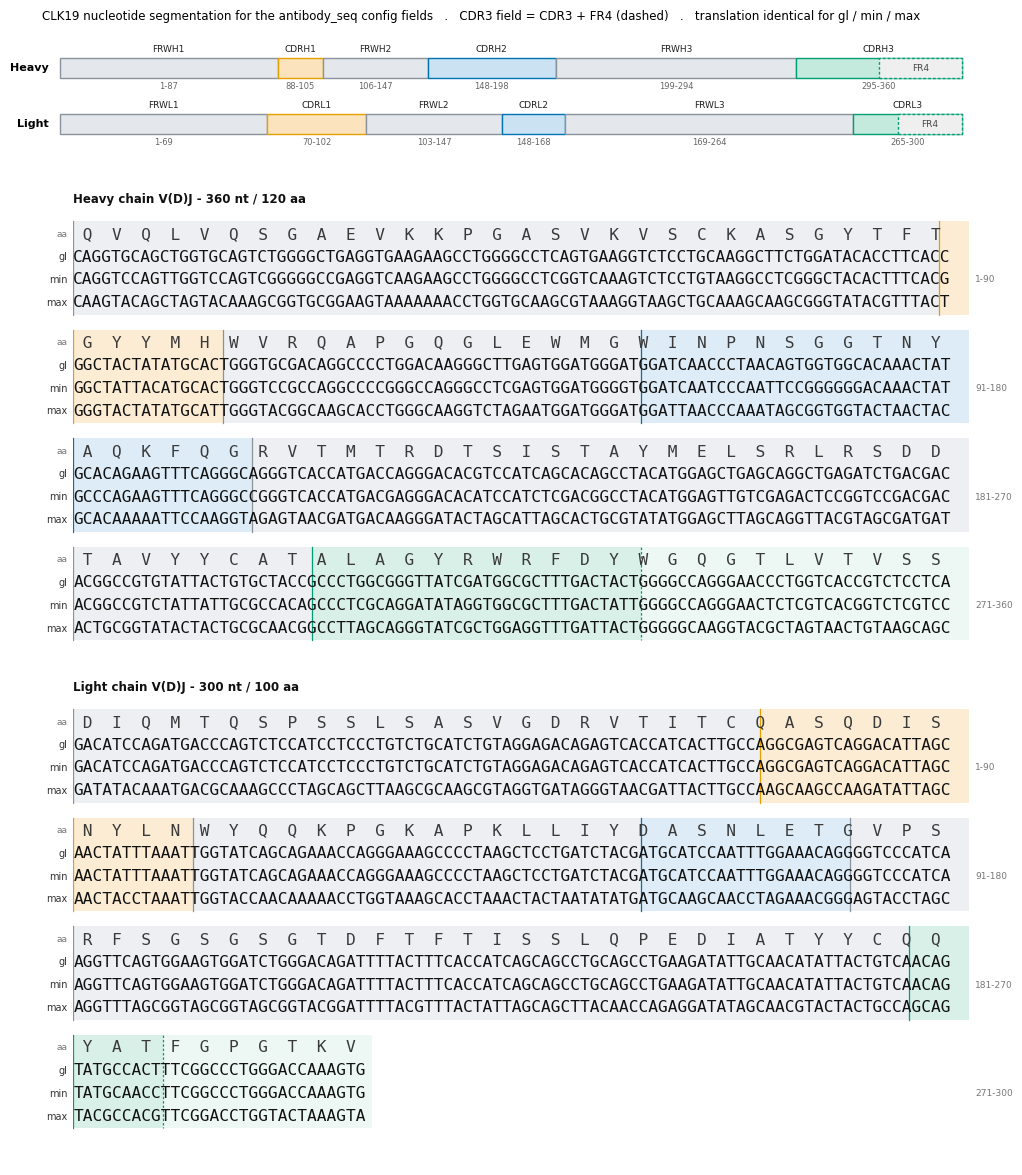

In [15]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

CONV = "template_compatible"
FILL = {"FR": "#E4E7EB", "CDR1": "#FBE3BE", "CDR2": "#CBE2F3", "CDR3": "#C4E9DD"}
EDGE = {"FR": "#8A939C", "CDR1": "#E69F00", "CDR2": "#0072B2", "CDR3": "#009E73"}


def region_class(field):
    if "CDR" not in field:
        return "FR"
    return {"1": "CDR1", "2": "CDR2", "3": "CDR3"}[field[4]]


def spans(fields):
    out, off = [], 0
    for f in fields:
        L = len(SEGMENTED[(CONV, "gl")][f])
        out.append((f, off, off + L)); off += L
    return out


def fr4_offset(field):
    aa = translate(SEGMENTED[(CONV, "gl")][field])
    return 3 * (aa.find("WGQG") if field.startswith("CDRH") else re.search(r"FG.G", aa).start())


hc_sp, lc_sp = spans(HC_FIELDS), spans(LC_FIELDS)
WRAP, FW, FH = 90, 10.6, 12.2

layout, y = [], 0.0
for chain, sp, title in [("HC", hc_sp, "Heavy chain V(D)J - 360 nt / 120 aa"),
                         ("LC", lc_sp, "Light chain V(D)J - 300 nt / 100 aa")]:
    layout.append(("header", y, title, chain)); y += 1.45
    for ln in range(-(-sp[-1][2] // WRAP)):
        layout.append(("aa", y, ln, chain)); y += 1.0
        for v in VARIANTS:
            layout.append(("seq", y, ln, chain, v)); y += 1.0
        y += 0.75
    y += 0.9

fig = plt.figure(figsize=(FW, FH))
ax_s = fig.add_axes([0.075, 0.855, 0.885, 0.105])
ax_t = fig.add_axes([0.105, 0.030, 0.845, 0.800])
for a in (ax_s, ax_t):
    a.set_xticks([]); a.set_yticks([])
    for s in a.spines.values():
        s.set_visible(False)

ax_s.set_xlim(-0.02, 1.02); ax_s.set_ylim(-0.12, 2.05)
for row, (sp, lab, tot) in enumerate([(hc_sp, "Heavy", 360), (lc_sp, "Light", 300)]):
    yb, h = 1.25 - row * 0.95, 0.34
    for f, s, e in sp:
        c = region_class(f)
        ax_s.add_patch(Rectangle((s / tot, yb), (e - s) / tot, h, fc=FILL[c], ec=EDGE[c], lw=1.0, zorder=2))
        if c == "CDR3":
            b = (s + fr4_offset(f)) / tot
            ax_s.add_patch(Rectangle((b, yb), e / tot - b, h, fc="#EFEFEF", ec=EDGE[c],
                                     lw=1.0, ls=(0, (2, 1.5)), zorder=3))
            ax_s.text((b + e / tot) / 2, yb + h / 2, "FR4", ha="center", va="center",
                      fontsize=6.5, color="#4A4A4A", zorder=4)
        ax_s.text((s + e) / 2 / tot, yb + h + 0.07, f.replace("_nt", ""), ha="center",
                  va="bottom", fontsize=6.5, color="#222")
        ax_s.text((s + e) / 2 / tot, yb - 0.06, f"{s+1}-{e}", ha="center", va="top",
                  fontsize=6, color="#666")
    ax_s.text(-0.012, yb + h / 2, lab, ha="right", va="center", fontsize=8, fontweight="bold")
ax_s.set_title("CLK19 nucleotide segmentation for the antibody_seq config fields   .   "
               "CDR3 field = CDR3 + FR4 (dashed)   .   translation identical for gl / min / max",
               loc="left", fontsize=8.5, pad=8)

NROWS = y
ax_t.set_xlim(0, WRAP); ax_t.set_ylim(NROWS, 0)
FS = (0.845 * FW) / WRAP * 72 / 0.602 * 0.98
MONO = {"family": "DejaVu Sans Mono", "fontsize": FS}
spmap = {"HC": hc_sp, "LC": lc_sp}
fieldmap = {"HC": HC_FIELDS, "LC": LC_FIELDS}
for item in layout:
    kind, yy = item[0], item[1]
    if kind == "header":
        ax_t.text(0, yy + 0.45, item[2], fontsize=8.5, fontweight="bold", va="center", color="#111")
        continue
    ln, chain = item[2], item[3]
    sp = spmap[chain]; a = ln * WRAP; b = min(a + WRAP, sp[-1][2])
    full = {v: "".join(SEGMENTED[(CONV, v)][f] for f in fieldmap[chain]) for v in VARIANTS}
    if kind == "aa":
        ax_t.text(0, yy + 0.5, "".join(f" {translate(full['gl'][c:c+3])} " for c in range(a, b, 3)),
                  va="center", ha="left", color="#3A3A3A", **MONO)
        ax_t.text(-0.6, yy + 0.5, "aa", va="center", ha="right", fontsize=6.5, color="#777")
        for f, s0, e0 in sp:
            x0, x1 = max(s0, a), min(e0, b)
            if x1 > x0:
                c = region_class(f)
                ax_t.add_patch(Rectangle((x0 - a, yy - 0.05), x1 - x0, 4.1, fc=FILL[c],
                                         ec="none", alpha=0.65, zorder=0))
                if c == "CDR3":
                    bd = s0 + fr4_offset(f)
                    if a <= bd < b:
                        ax_t.add_patch(Rectangle((bd - a, yy - 0.05), min(e0, b) - bd, 4.1,
                                                 fc="#FFFFFF", ec="none", alpha=0.55, zorder=0))
                        ax_t.plot([bd - a, bd - a], [yy - 0.05, yy + 4.05], color=EDGE[c],
                                  lw=0.9, ls=(0, (2, 1.5)), zorder=1)
                ax_t.plot([x0 - a, x0 - a], [yy - 0.05, yy + 4.05], color=EDGE[c], lw=0.9, zorder=1)
        continue
    v = item[4]
    ax_t.text(0, yy + 0.5, full[v][a:b], va="center", ha="left", color="#111", zorder=2, **MONO)
    ax_t.text(-0.6, yy + 0.5, v, va="center", ha="right", fontsize=7, color="#333", zorder=2)
    if v == "max":
        ax_t.text(WRAP + 0.6, yy - 0.5, f"{a+1}-{b}", va="center", ha="left", fontsize=6.5, color="#777")

fig.savefig("CLK19_region_segmentation.png", dpi=220, bbox_inches="tight", facecolor="white")
print("wrote CLK19_region_segmentation.png")

## Methods paragraph

A draft for the manuscript — edit to taste, and check the convention name against whichever
JSON block you actually ran.

> **Sequence segmentation.** The heavy- and light-chain V(D)J nucleotide sequences
> (360 nt / 120 aa and 300 nt / 100 aa respectively) were translated and the resulting V
> domains numbered with ANARCI (Dunbar & Deane, 2016) under the Kabat scheme (Kabat *et al.*,
> 1991). Framework and CDR boundaries were taken from that numbering and transferred to the
> nucleotide sequences at codon resolution. Boundaries were verified by two independent
> routes: (i) direct location of the conserved Kabat delimiters — the invariant framework-1
> and framework-3 cysteines, the framework-2 tryptophan, and the J-region W-G-x-G / F-G-x-G
> motifs — which reproduced the full Kabat partition of both chains, and (ii) for the heavy chain, exact
> nucleotide identity with the correspondingly annotated IGHV1-2 fields of the reference
> simulation configuration, which matched without mismatch across FR1, CDR1, FR2 and CDR2.
> Two features of the simulation's field schema are noted: the CDR3 fields contain CDR3
> together with the J-encoded framework 4, as the schema provides no separate FR4 field; and
> the framework-1/CDR-H1 boundary is placed one residue N-terminal to canonical Kabat, so
> that Kabat position H30 falls in the CDR-H1 field. The synonymously recoded variants were
> confirmed to translate identically to the parental sequence at every field, and field
> lengths were identical across variants, so a single segmentation applies to all three.

### Caveats to keep in view

- **Constant regions are deliberately absent.** The schema covers V(D)J only. AID-driven
  somatic hypermutation is targeted to a window of roughly 1.5–2 kb downstream of the V
  promoter; the CH and CL exons lie outside it and are substrates for class-switch
  recombination, not SHM. Including them would generate mutations that do not occur in vivo.
- **Light-chain residue indices are offset by 2** relative to the reference antibody's
  config, because the reference's FR-L1 omits the first two residues (Step 4b). Any
  position-indexed comparison between the two antibodies must account for this.
- **The one-codon convention difference** (Step 3) shifts three nucleotides between
  `FRWH1_nt` and `CDRH1_nt`. If the simulation applies different mutation or selection
  weights to CDR versus framework fields, that codon's treatment changes with the choice.